In [ ]:
!pip -q install lifelines

import pandas as pd, numpy as np

BASE = "https://gdc-hub.s3.us-east-1.amazonaws.com/download/"   # replace if 404
surv = pd.read_csv(BASE + "TCGA-PAAD.survival.tsv.gz", sep="\t")
clin = pd.read_csv(BASE + "TCGA-PAAD.clinical.tsv.gz", sep="\t")

print("survival:", surv.shape)
print(surv.head())
print("\nclinical:", clin.shape)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
survival: (195, 4)
             sample  OS.time  OS      _PATIENT
0  TCGA-HZ-7922-01A      4.0   0  TCGA-HZ-7922
1  TCGA-HZ-A8P1-01A      7.0   0  TCGA-HZ-A8P1
2  TCGA-IB-AAUM-01A      8.0   0  TCGA-IB-AAUM
3  TCGA-RL-AAAS-01A      9.0   0  TCGA-RL-AAAS
4  TCGA-US-A77G-01A     12.0   1  TCGA-US-A77G

clinical: (196, 89)


In [ ]:
# 1. Survival table: how many events vs censored?
print(surv.columns.tolist())
print(surv["OS"].value_counts())          # 1 = died, 0 = censored
print(surv["OS.time"].describe())         # days

# 2. Find the histology and stage columns (names vary)
keys = ["diagnosis", "histolog", "stage", "age", "gender", "sample_type"]
cols = [c for c in clin.columns if any(k in c.lower() for k in keys)]
print(cols)

['sample', 'OS.time', 'OS', '_PATIENT']
OS
1    108
0     87
Name: count, dtype: int64
count     195.000000
mean      565.092308
std       463.597777
min         4.000000
25%       282.000000
50%       467.000000
75%       673.500000
max      2741.000000
Name: OS.time, dtype: float64
['gender.demographic', 'age_at_index.demographic', 'ajcc_pathologic_stage.diagnoses', 'days_to_diagnosis.diagnoses', 'age_at_diagnosis.diagnoses', 'primary_diagnosis.diagnoses', 'year_of_diagnosis.diagnoses', 'age_at_earliest_diagnosis.diagnoses.xena_derived', 'age_at_earliest_diagnosis_in_years.diagnoses.xena_derived', 'sample_type_id.samples', 'sample_type.samples']


In [ ]:
# TCGA barcode: characters 14-15 of the sample ID = sample type
# 01 = primary tumor, 06 = metastatic, 11 = solid normal
surv["sample_code"] = surv["sample"].str[13:15]
print(surv["sample_code"].value_counts())

# Duplicates: patients appearing more than once
print("unique patients:", surv["_PATIENT"].nunique(), "of", len(surv))
print(surv[surv["_PATIENT"].duplicated(keep=False)])

# Clinical side
print(clin["sample_type.samples"].value_counts())
print(clin["primary_diagnosis.diagnoses"].value_counts())
print(clin["ajcc_pathologic_stage.diagnoses"].value_counts(dropna=False))

sample_code
01    184
11     10
06      1
Name: count, dtype: int64
unique patients: 184 of 195
               sample  OS.time  OS      _PATIENT sample_code
8    TCGA-FZ-5920-11A     61.0   1  TCGA-FZ-5920          11
9    TCGA-FZ-5920-01A     61.0   1  TCGA-FZ-5920          01
20   TCGA-HV-A5A3-01A    128.0   1  TCGA-HV-A5A3          01
21   TCGA-HV-A5A3-11A    128.0   1  TCGA-HV-A5A3          11
64   TCGA-YB-A89D-01A    350.0   0  TCGA-YB-A89D          01
65   TCGA-YB-A89D-11A    350.0   0  TCGA-YB-A89D          11
75   TCGA-H6-8124-11A    392.0   0  TCGA-H6-8124          11
76   TCGA-H6-8124-01A    392.0   0  TCGA-H6-8124          01
81   TCGA-H6-A45N-01A    397.0   1  TCGA-H6-A45N          01
82   TCGA-H6-A45N-11A    397.0   1  TCGA-H6-A45N          11
101  TCGA-FZ-5924-11A    480.0   1  TCGA-FZ-5924          11
102  TCGA-FZ-5924-01A    480.0   1  TCGA-FZ-5924          01
119  TCGA-FZ-5926-11A    541.0   1  TCGA-FZ-5926          11
120  TCGA-FZ-5926-01A    541.0   1  TCGA-FZ-5926  

In [ ]:
# Xena's first clinical column is the sample ID; verify with the print
print(clin.columns[:3].tolist())
clin = clin.rename(columns={clin.columns[0]: "sample"})

# Rule 1: primary tumours only, so one row per patient
s = surv[surv["sample_code"] == "01"].copy()

cols = ["sample", "primary_diagnosis.diagnoses", "ajcc_pathologic_stage.diagnoses",
        "age_at_index.demographic", "gender.demographic"]
df = s.merge(clin[cols], on="sample", how="inner")
print("after merge:", len(df), "patients,", df["_PATIENT"].nunique(), "unique")
print(df["primary_diagnosis.diagnoses"].value_counts())

# Rule 2 and 3: keep ductal adenocarcinoma only
KEEP = ["Infiltrating duct carcinoma, NOS", "Adenocarcinoma, NOS"]
df = df[df["primary_diagnosis.diagnoses"].isin(KEEP)].copy()
print("\nPDAC cohort:", len(df), "patients,", int(df["OS"].sum()), "deaths")

# Rule 4: just count early deaths for now, no dropping yet
print("OS.time < 30 days:", (df["OS.time"] < 30).sum())
print(df[["OS.time", "OS"]].describe())

['sample', 'id', 'disease_type']
after merge: 184 patients, 184 unique
primary_diagnosis.diagnoses
Infiltrating duct carcinoma, NOS      149
Adenocarcinoma, NOS                    20
Neuroendocrine carcinoma, NOS           8
Mucinous adenocarcinoma                 5
Carcinoma, undifferentiated, NOS        1
Adenocarcinoma with mixed subtypes      1
Name: count, dtype: int64

PDAC cohort: 169 patients, 96 deaths
OS.time < 30 days: 5
           OS.time          OS
count   169.000000  169.000000
mean    521.485207    0.568047
std     399.464196    0.496820
min       4.000000    0.000000
25%     267.000000    0.000000
50%     462.000000    1.000000
75%     660.000000    1.000000
max    2285.000000    1.000000


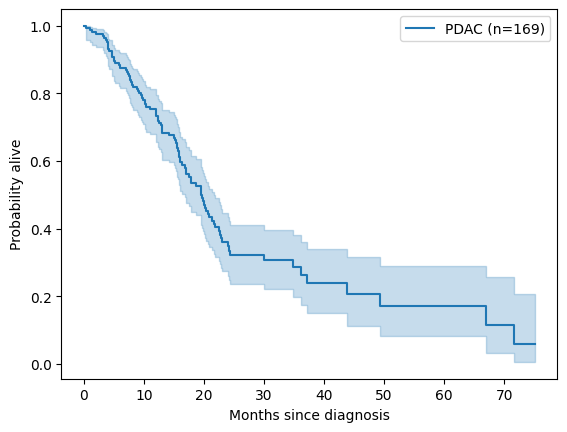

naive median of follow-up (months): 15.2
KM median survival (months): 19.6
12    0.747418
24    0.360176
36    0.285406
Name: PDAC (n=169), dtype: float64


In [ ]:
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

months = df["OS.time"] / 30.44        # days to months
kmf = KaplanMeierFitter()
kmf.fit(months, df["OS"], label=f"PDAC (n={len(df)})")

ax = kmf.plot_survival_function()
ax.set_xlabel("Months since diagnosis")
ax.set_ylabel("Probability alive")
plt.show()

# naive median vs KM median
print("naive median of follow-up (months):", round(months.median(), 1))
print("KM median survival (months):", round(kmf.median_survival_time_, 1))
print(kmf.survival_function_at_times([12, 24, 36]))

In [ ]:
from lifelines import CoxPHFitter

d = df.copy()
d = d[d["ajcc_pathologic_stage.diagnoses"].notna()]   # 3 missing stages, drop and report

# Group stages. IIB is the reference (the largest group).
stage = d["ajcc_pathologic_stage.diagnoses"]
d["stage_I"]    = stage.isin(["Stage I", "Stage IA", "Stage IB"]).astype(int)
d["stage_IIA"]  = (stage == "Stage IIA").astype(int)
d["stage_III_IV"] = stage.isin(["Stage III", "Stage IV"]).astype(int)
d["male"] = (d["gender.demographic"] == "male").astype(int)
d["age"]  = d["age_at_index.demographic"]

model_cols = ["OS.time", "OS", "age", "male", "stage_I", "stage_IIA", "stage_III_IV"]
print("patients:", len(d), "deaths:", int(d["OS"].sum()))

cph = CoxPHFitter()
cph.fit(d[model_cols], duration_col="OS.time", event_col="OS")
cph.print_summary(decimals=2)
print("C-index:", round(cph.concordance_index_, 3))

patients: 167 deaths: 96


<lifelines.CoxPHFitter: fitted with 167 total observations, 71 right-censored observations>
             duration col = 'OS.time'
                event col = 'OS'
      baseline estimation = breslow
   number of observations = 167
number of events observed = 96
   partial log-likelihood = -405.29
         time fit was run = 2026-11-02 14:04:43 UTC

---
              coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                     
age           0.02      1.02      0.01            0.00            0.04                1.00                1.04
male         -0.18      0.84      0.21           -0.58            0.23                0.56                1.26
stage_I      -0.21      0.81      0.43           -1.05            0.63                0.35                1.88
stage_IIA    -0.59      0.56      0.32           -1.21            0.03                0.30                1.03
stage_III_IV -0.25      0.78      0.47           -1.16            0.66                0.31                1.94

              cmp to     z    p  -log2(p)
covariate                                
age             0.00  2.06 0.04      4.65
male            0.00 -0.84 0.40      1.33
stage_I         0.00 -0.49 0.63      0.68
stage_IIA       0.00 -1.87 0.06      4.01
stage_III_IV    0.00 -0.53 0.59      0.75
---
Concordance = 0.58
Partial AIC = 820.57
log-likelihood ratio test = 9.03 on 5 df
-log2(p) of ll-ratio test = 3.21

C-index: 0.582


In [ ]:
from lifelines import CoxPHFitter

d = df.copy()
d = d[d["ajcc_pathologic_stage.diagnoses"].notna()]   # 3 missing stages, drop and report

# Group stages. IIB is the reference (the largest group).
stage = d["ajcc_pathologic_stage.diagnoses"]
d["stage_I"]    = stage.isin(["Stage I", "Stage IA", "Stage IB"]).astype(int)
d["stage_IIA"]  = (stage == "Stage IIA").astype(int)
d["stage_III_IV"] = stage.isin(["Stage III", "Stage IV"]).astype(int)
d["male"] = (d["gender.demographic"] == "male").astype(int)
d["age"]  = d["age_at_index.demographic"]

model_cols = ["OS.time", "OS", "age", "male", "stage_I", "stage_IIA", "stage_III_IV"]
print("patients:", len(d), "deaths:", int(d["OS"].sum()))

cph = CoxPHFitter()
cph.fit(d[model_cols], duration_col="OS.time", event_col="OS")
cph.print_summary(decimals=2)
print("C-index:", round(cph.concordance_index_, 3))

patients: 167 deaths: 96


<lifelines.CoxPHFitter: fitted with 167 total observations, 71 right-censored observations>
             duration col = 'OS.time'
                event col = 'OS'
      baseline estimation = breslow
   number of observations = 167
number of events observed = 96
   partial log-likelihood = -405.29
         time fit was run = 2026-11-02 14:10:00 UTC

---
              coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                     
age           0.02      1.02      0.01            0.00            0.04                1.00                1.04
male         -0.18      0.84      0.21           -0.58            0.23                0.56                1.26
stage_I      -0.21      0.81      0.43           -1.05            0.63                0.35                1.88
stage_IIA    -0.59      0.56      0.32           -1.21            0.03                0.30                1.03
stage_III_IV -0.25      0.78      0.47           -1.16            0.66                0.31                1.94

              cmp to     z    p  -log2(p)
covariate                                
age             0.00  2.06 0.04      4.65
male            0.00 -0.84 0.40      1.33
stage_I         0.00 -0.49 0.63      0.68
stage_IIA       0.00 -1.87 0.06      4.01
stage_III_IV    0.00 -0.53 0.59      0.75
---
Concordance = 0.58
Partial AIC = 820.57
log-likelihood ratio test = 9.03 on 5 df
-log2(p) of ll-ratio test = 3.21

C-index: 0.582


In [8]:
expr = pd.read_csv(BASE + "TCGA-PAAD.star_fpkm.tsv.gz", sep="\t", index_col=0)
print(expr.shape)                    # genes x samples
print(expr.iloc[:3, :3])
print("max value:", expr.values.max())   # tells us if it is already log-transformed

# Keep only samples in our cohort (columns), in the same order as df
keep = [s for s in df["sample"] if s in expr.columns]
print("cohort samples found in expression:", len(keep), "of", len(df))
X = expr[keep].T                     # now patients x genes
print(X.shape)

(60660, 183)
                    TCGA-IB-A6UG-01A  TCGA-3A-A9IU-01A  TCGA-FB-A545-01A
Ensembl_ID                                                              
ENSG00000000003.15          3.746022          4.085595          3.009491
ENSG00000000005.6           0.000000          0.019204          0.000000
ENSG00000000419.13          4.378734          4.787730          4.874905
max value: 17.197842589542763
cohort samples found in expression: 162 of 169
(162, 60660)


In [10]:
# Patient ID = first 12 characters of the barcode
expr_pat = pd.Series(expr.columns, index=[c[:12] for c in expr.columns])

missing = df[~df["sample"].isin(expr.columns)]
print("missing samples:", missing["sample"].tolist())

# Are the same PATIENTS in the expression table under a different sample ID?
found_by_patient = [p for p in missing["_PATIENT"] if p in expr_pat.index]
print("recoverable by patient ID:", len(found_by_patient), "of", len(missing))
print(expr_pat[expr_pat.index.isin(missing["_PATIENT"])])

missing samples: ['TCGA-FZ-5920-01A', 'TCGA-FZ-5921-01A', 'TCGA-FZ-5924-01A', 'TCGA-FZ-5926-01A', 'TCGA-FZ-5923-01A', 'TCGA-FZ-5919-01A', 'TCGA-FZ-5922-01A']
recoverable by patient ID: 0 of 7
Series([], dtype: object)


In [11]:
# Final cohort = complete stage/age/sex AND expression
d = d[d["sample"].isin(expr.columns)].copy()
d["TSS"] = d["sample"].str[5:7]          # tissue source site (batch variable)
print("final cohort:", len(d), "patients,", int(d["OS"].sum()), "deaths")
print("deaths per clinical variable:", round(d["OS"].sum() / 5, 1))
print(d["TSS"].value_counts())

# Same baseline model, now on the exact cohort the expression model will use
cph = CoxPHFitter()
cph.fit(d[model_cols], duration_col="OS.time", event_col="OS")
print("baseline C-index (in-sample, optimistic):", round(cph.concordance_index_, 3))

# Expression matrix aligned row-for-row with d
X = expr[d["sample"]].T
print(X.shape, "| rows match cohort order:", (X.index == d["sample"].values).all())

final cohort: 160 patients, 89 deaths
deaths per clinical variable: 17.8
TSS
IB    38
HZ    28
FB    16
2J    15
3A     9
HV     8
F2     8
2L     5
US     5
XD     4
LB     3
S4     3
XN     2
Q3     2
H6     2
3E     2
RL     1
RB     1
YB     1
OE     1
L1     1
Z5     1
M8     1
PZ     1
H8     1
YY     1
Name: count, dtype: int64
baseline C-index (in-sample, optimistic): 0.585
(160, 60660) | rows match cohort order: True
